# Проект №4: удаление шума с камеры видеонаблюдения в условиях низкой освещённости

**Дисциплина:** Компьютерное зрение 1. Ноутбук рассчитан на Google Colab, запускать ячейки сверху вниз.

## 1. Постановка задачи

Камеры видеонаблюдения ночью или в тёмных помещениях дают тёмный и шумный кадр: фотонов мало, поэтому на изображении
виден **дробовой шум** (Пуассона) и **шум считывания** матрицы (Гаусса). Простое повышение яркости усиливает шум вместе с сигналом.

**Цель:** построить программу, которая убирает шум и делает кадр пригодным для просмотра, используя только классические методы CV (без нейросетей).

**Что делаем:**
1. Моделируем съёмку при слабом свете (эталон известен, поэтому можно считать PSNR и SSIM).
2. Сравниваем 4 фильтра: Гаусс, медиана, билатеральный, Non-Local Means (NLM).
3. Для видео добавляем адаптивное временное усреднение с маской движения.
4. Повышаем яркость (адаптивная гамма и CLAHE) **после** шумоподавления.
5. Проверяем на разных уровнях освещённости, на нестандартных случаях и измеряем время.

**Почему классические методы:** они быстрые, не требуют обучающей выборки и их работу можно объяснить. Для видеонаблюдения
важна скорость, а соседние кадры статичной камеры дают дополнительную информацию, которую нейросеть по одному кадру не использует.

In [1]:
import time

import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.metrics import peak_signal_noise_ratio as psnr, structural_similarity as ssim

rng = np.random.default_rng(42)
PHOTONS = 400.0   # условное число фотонов при полной яркости пикселя (чем меньше, тем шумнее)


def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def load_test_images(size=(384, 288)):
    raw = {"astronaut": data.astronaut(), "coffee": data.coffee(), "chelsea": data.chelsea()}
    return {k: cv2.resize(cv2.cvtColor(v, cv2.COLOR_RGB2BGR), size, interpolation=cv2.INTER_AREA)
            for k, v in raw.items()}


def simulate_low_light(img, brightness=0.12, read_sigma=2.0):
    # Тёмная сцена + шум Пуассона (дробовой) + гауссов шум считывания
    x = img.astype(np.float32) / 255.0 * brightness
    shot = rng.poisson(x * PHOTONS).astype(np.float32) / PHOTONS
    read = rng.normal(0, read_sigma / 255.0, img.shape).astype(np.float32)
    return np.clip((shot + read) * 255, 0, 255).round().astype(np.uint8)


def to_ref_scale(img, brightness):
    # Только для метрик: возвращаем яркость к исходной, чтобы сравнить с эталоном
    return np.clip(img.astype(np.float32) / brightness, 0, 255).astype(np.uint8)


def quality(ref, out):
    return (psnr(ref, out, data_range=255),
            ssim(ref, out, channel_axis=2, data_range=255))


imgs = load_test_images()
print({k: v.shape for k, v in imgs.items()})

{'astronaut': (288, 384, 3), 'coffee': (288, 384, 3), 'chelsea': (288, 384, 3)}


## 2. Модель шума при слабом свете

Кадр умножается на коэффициент яркости (`brightness`), затем добавляется шум Пуассона (чем темнее, тем он относительно сильнее)
и гауссов шум считывания. Исходное хорошо освещённое изображение хранится как **эталон**, по нему считаем **PSNR** (чем выше, тем лучше)
и **SSIM** (структурное сходство, от 0 до 1).

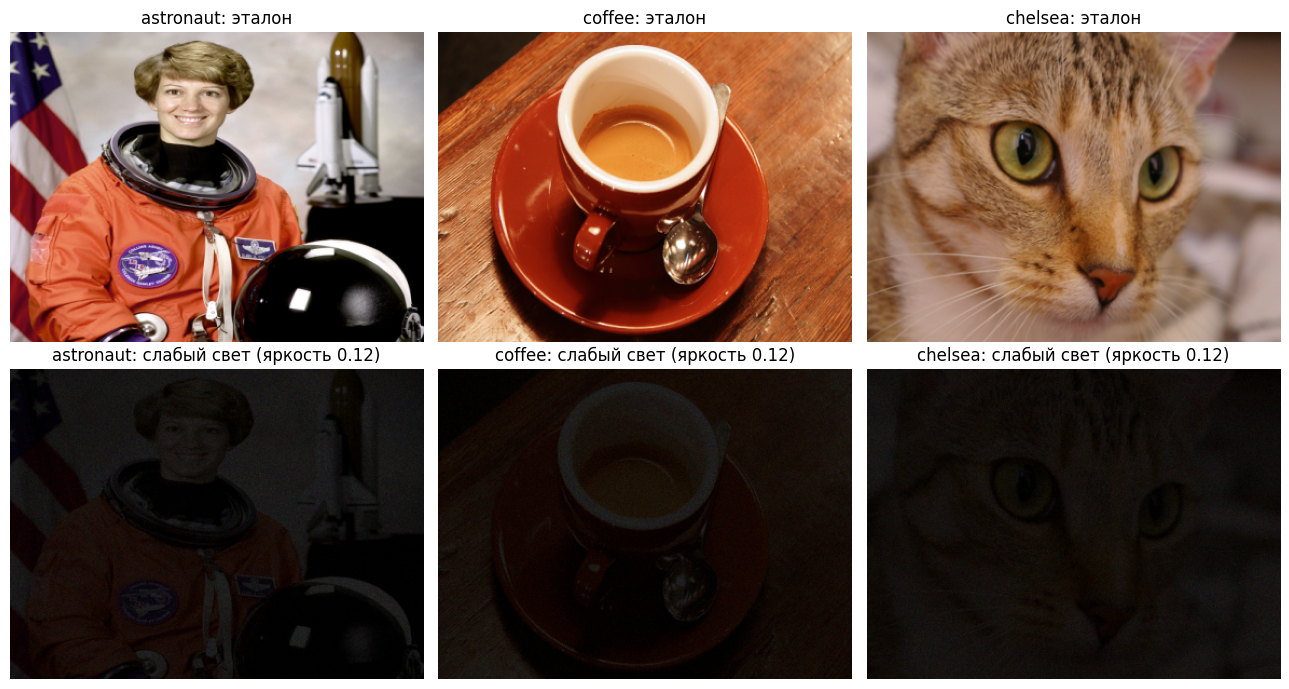

In [2]:
BRIGHT = 0.12
fig, axs = plt.subplots(2, 3, figsize=(13, 7))
for j, (name, img) in enumerate(imgs.items()):
    noisy = simulate_low_light(img, BRIGHT)
    axs[0, j].imshow(rgb(img)); axs[0, j].set_title(f"{name}: эталон")
    axs[1, j].imshow(rgb(noisy)); axs[1, j].set_title(f"{name}: слабый свет (яркость {BRIGHT})")
    for i in range(2):
        axs[i, j].axis("off")
plt.tight_layout(); plt.show()

## 3. Методы шумоподавления

| Метод | Идея | Сильная сторона | Ограничение |
|---|---|---|---|
| Гаусс | усреднение с весами по расстоянию | быстрый | размывает края |
| Медиана | медиана в окне | убирает выбросы | теряет мелкие детали |
| Билатеральный | веса по расстоянию и по разнице яркости | сохраняет края, быстрее NLM | параметры нужно подбирать под уровень шума |
| NLM | усреднение похожих **патчей** по всему окну поиска | лучшее качество | самый медленный |

Параметр `h` у NLM задаёт силу сглаживания и должен соответствовать уровню шума. Ниже проверим это на сетке значений.

h= 3  PSNR=19.43  SSIM=0.410
h= 5  PSNR=24.42  SSIM=0.708
h= 7  PSNR=25.95  SSIM=0.806
h= 9  PSNR=25.64  SSIM=0.796
h=12  PSNR=24.28  SSIM=0.753


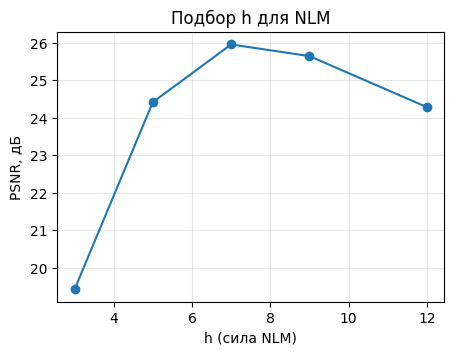

In [3]:
def d_gauss(img):    return cv2.GaussianBlur(img, (5, 5), 0)
def d_median(img):   return cv2.medianBlur(img, 5)
def d_bilateral(img): return cv2.bilateralFilter(img, 9, 25, 5)
def d_nlm(img, h=7): return cv2.fastNlMeansDenoisingColored(img, None, h, h, 7, 21)

METHODS = {"Гаусс": d_gauss, "Медиана": d_median, "Билатеральный": d_bilateral, "NLM": d_nlm}

# --- подбор параметра h для NLM ---
test = imgs["astronaut"]
noisy = simulate_low_light(test, BRIGHT)
hs = [3, 5, 7, 9, 12]
res_h = [quality(test, to_ref_scale(d_nlm(noisy, h), BRIGHT)) for h in hs]
for h, (p, s) in zip(hs, res_h):
    print(f"h={h:2d}  PSNR={p:.2f}  SSIM={s:.3f}")

plt.figure(figsize=(5, 3.5))
plt.plot(hs, [r[0] for r in res_h], "o-")
plt.xlabel("h (сила NLM)"); plt.ylabel("PSNR, дБ"); plt.title("Подбор h для NLM"); plt.grid(alpha=.3)
plt.show()

## 4. Сравнение методов на трёх изображениях (кадр + шум -> фильтр -> метрики)

Изображение Метод             PSNR   SSIM     мс
astronaut   Без обработки    19.24  0.394      0
astronaut   Гаусс            25.83  0.663     12
astronaut   Медиана          24.83  0.697     15
astronaut   Билатеральный    25.94  0.690     86
astronaut   NLM              25.96  0.806   1318
coffee      Без обработки    19.57  0.317      0
coffee      Гаусс            26.86  0.659      1
coffee      Медиана          25.84  0.632      2
coffee      Билатеральный    27.24  0.698     29
coffee      NLM              26.41  0.713    794
chelsea     Без обработки    18.66  0.250      0
chelsea     Гаусс            28.43  0.686      1
chelsea     Медиана          27.93  0.662      4
chelsea     Билатеральный    29.27  0.738     42
chelsea     NLM              27.63  0.732    433


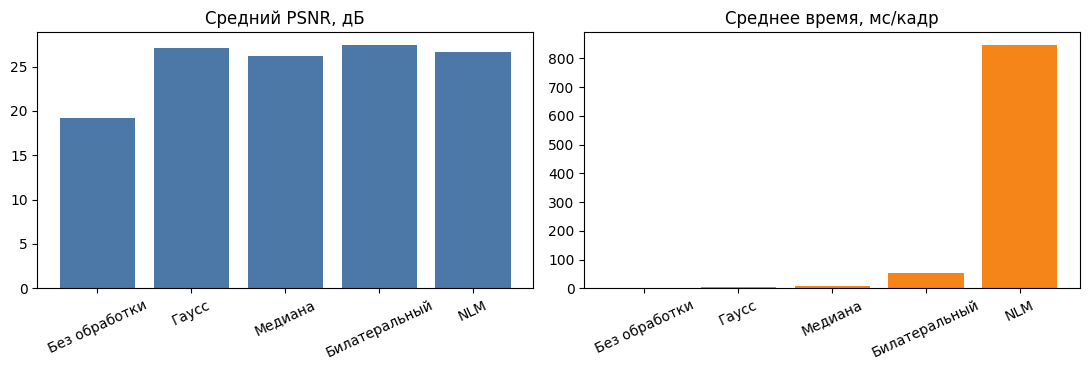

In [4]:
rows = []
for name, img in imgs.items():
    noisy = simulate_low_light(img, BRIGHT)
    p0, s0 = quality(img, to_ref_scale(noisy, BRIGHT))
    rows.append((name, "Без обработки", p0, s0, 0.0))
    for mname, fn in METHODS.items():
        t0 = time.perf_counter(); out = fn(noisy); dt = (time.perf_counter() - t0) * 1000
        p, s = quality(img, to_ref_scale(out, BRIGHT))
        rows.append((name, mname, p, s, dt))

print(f"{'Изображение':11s} {'Метод':15s} {'PSNR':>6s} {'SSIM':>6s} {'мс':>6s}")
for r in rows:
    print(f"{r[0]:11s} {r[1]:15s} {r[2]:6.2f} {r[3]:6.3f} {r[4]:6.0f}")

# усреднение по изображениям
names = ["Без обработки"] + list(METHODS)
avg_psnr = [np.mean([r[2] for r in rows if r[1] == n]) for n in names]
avg_ms = [np.mean([r[4] for r in rows if r[1] == n]) for n in names]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(names, avg_psnr, color="#4C78A8"); ax[0].set_title("Средний PSNR, дБ"); ax[0].tick_params(axis="x", rotation=25)
ax[1].bar(names, avg_ms, color="#F58518"); ax[1].set_title("Среднее время, мс/кадр"); ax[1].tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

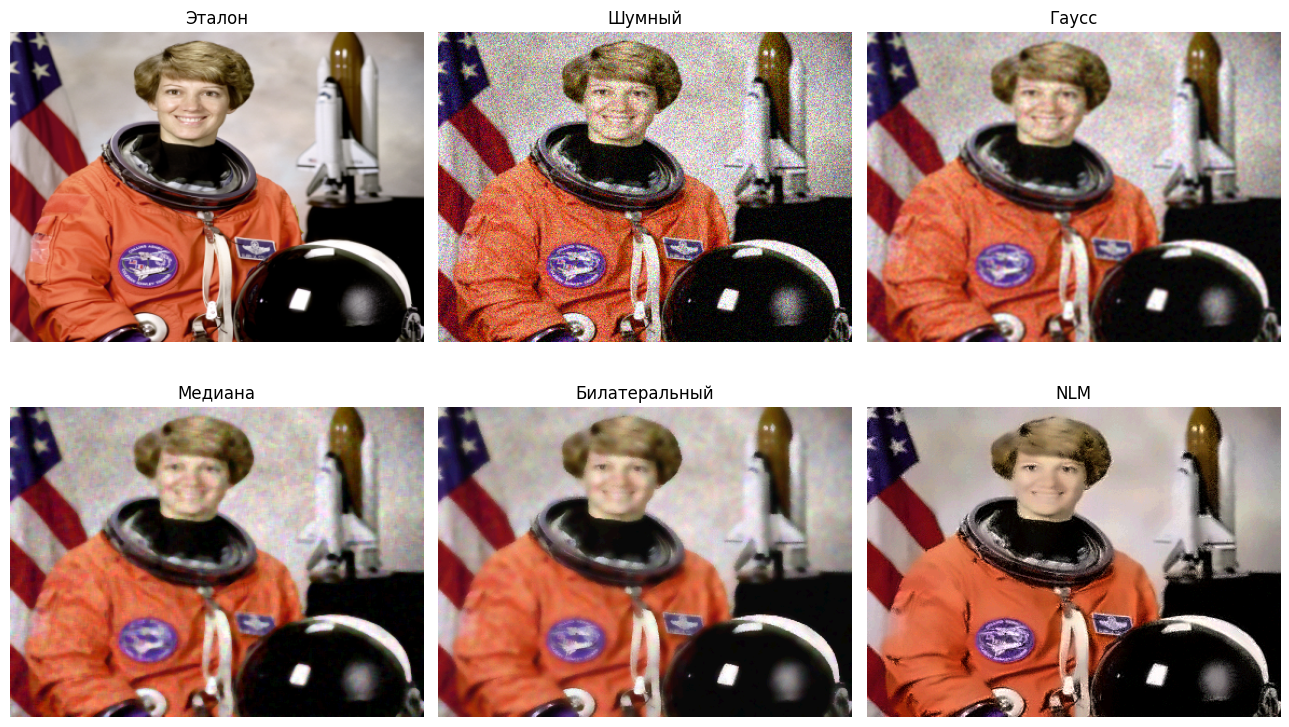

In [5]:
# визуальное сравнение (с яркостью, приведённой к норме, чтобы было видно разницу)
img = imgs["astronaut"]; noisy = simulate_low_light(img, BRIGHT)
panels = [("Эталон", img), ("Шумный", to_ref_scale(noisy, BRIGHT))] + \
         [(n, to_ref_scale(f(noisy), BRIGHT)) for n, f in METHODS.items()]
fig, axs = plt.subplots(2, 3, figsize=(13, 8))
for ax, (t, im) in zip(axs.ravel(), panels):
    ax.imshow(rgb(im)); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()

**Что видно по таблице (проверьте на своих цифрах):** все фильтры сильно улучшают шумный кадр. По SSIM NLM чаще всего лучше сохраняет
структуру, а по PSNR билатеральный фильтр сопоставим с NLM или даже выше, при этом работает примерно в 15-25 раз быстрее. Гаусс и медиана
почти не требуют времени, но размывают детали (ниже SSIM). Значит, выбор метода зависит от требований: качество структуры или скорость.

## 5. Повышение яркости: порядок операций важен

Гамма-коррекция и CLAHE (адаптивное выравнивание контраста по блокам) усиливают всё, **в том числе шум**.
Поэтому правильный порядок: **сначала шумоподавление, потом повышение яркости**. Проверим это.

Яркость повышается адаптивно: гамма подбирается так, чтобы средняя яркость кадра стала около 110, затем CLAHE применяется
к каналу L цветового пространства LAB (чтобы не искажать цвета).

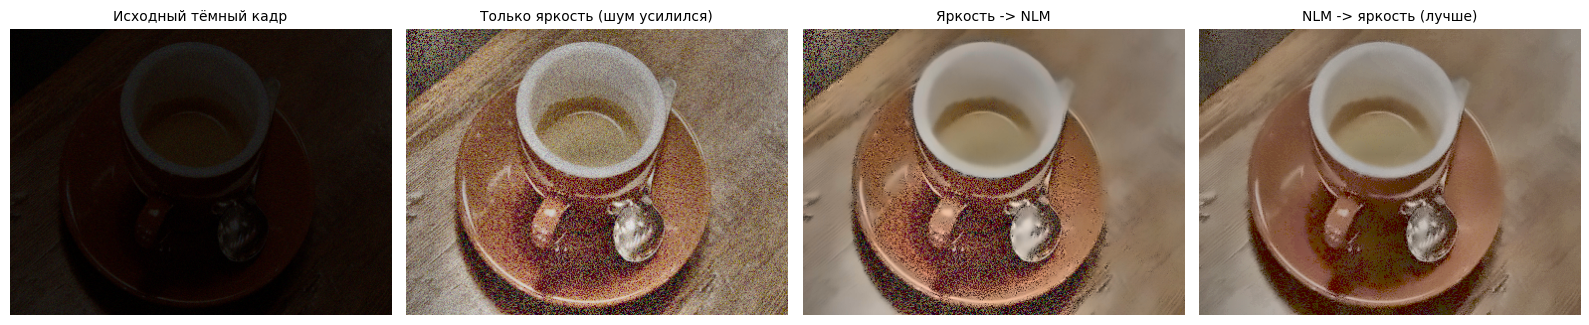

SSIM с эталоном (яркость-first): 0.431   (шумоподавление-first): 0.528


In [6]:
def enhance(img, target=110, clip=2.0):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    m = max(float(gray.mean()), 1.0)
    gamma = float(np.clip(np.log(target / 255.0) / np.log(m / 255.0), 0.2, 1.0))
    lut = ((np.arange(256) / 255.0) ** gamma * 255).astype(np.uint8)
    out = cv2.LUT(img, lut)
    l, a, b = cv2.split(cv2.cvtColor(out, cv2.COLOR_BGR2LAB))
    l = cv2.createCLAHE(clipLimit=clip, tileGridSize=(8, 8)).apply(l)
    return cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2BGR)


img = imgs["coffee"]; noisy = simulate_low_light(img, BRIGHT)
a_enh_first = d_nlm(enhance(noisy), h=12)       # сначала яркость, потом шумоподавление
b_den_first = enhance(d_nlm(noisy, h=7))        # сначала шумоподавление, потом яркость
panels = [("Исходный тёмный кадр", noisy), ("Только яркость (шум усилился)", enhance(noisy)),
          ("Яркость -> NLM", a_enh_first), ("NLM -> яркость (лучше)", b_den_first)]
fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for ax, (t, im) in zip(axs, panels):
    ax.imshow(rgb(im)); ax.set_title(t, fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()
print("SSIM с эталоном (яркость-first):", round(quality(img, a_enh_first)[1], 3),
      "  (шумоподавление-first):", round(quality(img, b_den_first)[1], 3))

## 6. Видео: временное шумоподавление с маской движения

Камера видеонаблюдения обычно **неподвижна**, а значит, фон одинаков в соседних кадрах, а шум разный. Усреднение по времени
снижает шум примерно в корень из N раз без размытия деталей. Но движущиеся объекты при таком усреднении оставляют «шлейф» (ghosting).

**Алгоритм (комбинация методов):**
1. Для каждого предыдущего кадра окна считаем вес по разнице с текущим кадром (после лёгкого размытия): похожие пиксели получают вес близко к 1, отличающиеся (движение) близко к 0.
2. Взвешенное временное среднее + лёгкий NLM даёт результат на статичных областях.
3. **Маска движения** (порог по среднему весу, морфология: открытие и расширение) отделяет движущиеся области.
4. В областях движения используется только пространственный NLM по текущему кадру.

Тестовое видео синтетическое (фон + движущийся «человек»), поэтому есть эталон. Свои видео можно проверить в конце ноутбука.

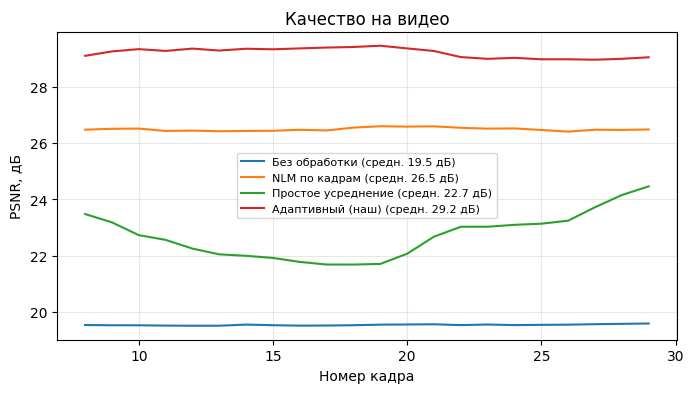

Без обработки        PSNR=19.54 дБ   время=0 мс/кадр
NLM по кадрам        PSNR=26.49 дБ   время=433 мс/кадр
Простое усреднение   PSNR=22.71 дБ   время=5 мс/кадр
Адаптивный (наш)     PSNR=29.21 дБ   время=914 мс/кадр


In [7]:
def make_video(bg, n=30):
    frames, h, w = [], *bg.shape[:2]
    for t in range(n):
        f = bg.copy()
        x = int(20 + (w - 120) * t / (n - 1))
        cv2.rectangle(f, (x, 100), (x + 60, 200), (40, 40, 200), -1)   # "тело"
        cv2.circle(f, (x + 30, 90), 18, (190, 170, 150), -1)           # "голова"
        frames.append(f)
    return frames


def temporal_denoise(frames, t, k=8, tau=10.0, h_static=3, h_motion=7):
    cur = frames[t]
    win = frames[max(0, t - k + 1):t + 1]
    cs = cv2.GaussianBlur(cur, (7, 7), 0).astype(np.float32)
    num = np.zeros(cur.shape, np.float32)
    den = np.zeros(cur.shape[:2], np.float32)
    for f in win:
        fs = cv2.GaussianBlur(f, (7, 7), 0).astype(np.float32)
        d = np.sqrt(((fs - cs) ** 2).sum(axis=2))
        w = np.exp(-(d / tau) ** 2)
        num += w[..., None] * f
        den += w
    avg = (num / den[..., None]).round().astype(np.uint8)

    motion = ((den / len(win)) < 0.6).astype(np.uint8)
    motion = cv2.morphologyEx(motion, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    motion = cv2.dilate(motion, np.ones((5, 5), np.uint8))

    static_part = d_nlm(avg, h_static)
    moving_part = d_nlm(cur, h_motion)
    out = np.where(motion[..., None] > 0, moving_part, static_part).astype(np.uint8)
    return out, motion


def naive_temporal(frames, t, k=8):
    return np.mean(frames[max(0, t - k + 1):t + 1], axis=0).round().astype(np.uint8)


bg = imgs["coffee"]
clean = make_video(bg, 30)
noisy_v = [simulate_low_light(f, BRIGHT) for f in clean]

methods_v = {
    "Без обработки": lambda t: noisy_v[t],
    "NLM по кадрам": lambda t: d_nlm(noisy_v[t]),
    "Простое усреднение": lambda t: naive_temporal(noisy_v, t),
    "Адаптивный (наш)": lambda t: temporal_denoise(noisy_v, t)[0],
}
START = 8   # с этого кадра окно заполнено
curves = {k: [] for k in methods_v}
times = {k: [] for k in methods_v}
for t in range(START, len(clean)):
    for k, fn in methods_v.items():
        t0 = time.perf_counter(); out = fn(t); times[k].append((time.perf_counter() - t0) * 1000)
        curves[k].append(psnr(clean[t], to_ref_scale(out, BRIGHT), data_range=255))

plt.figure(figsize=(8, 4))
for k, v in curves.items():
    plt.plot(range(START, len(clean)), v, label=f"{k} (средн. {np.mean(v):.1f} дБ)")
plt.xlabel("Номер кадра"); plt.ylabel("PSNR, дБ"); plt.legend(fontsize=8); plt.grid(alpha=.3)
plt.title("Качество на видео"); plt.show()
for k in methods_v:
    print(f"{k:20s} PSNR={np.mean(curves[k]):.2f} дБ   время={np.mean(times[k]):.0f} мс/кадр")

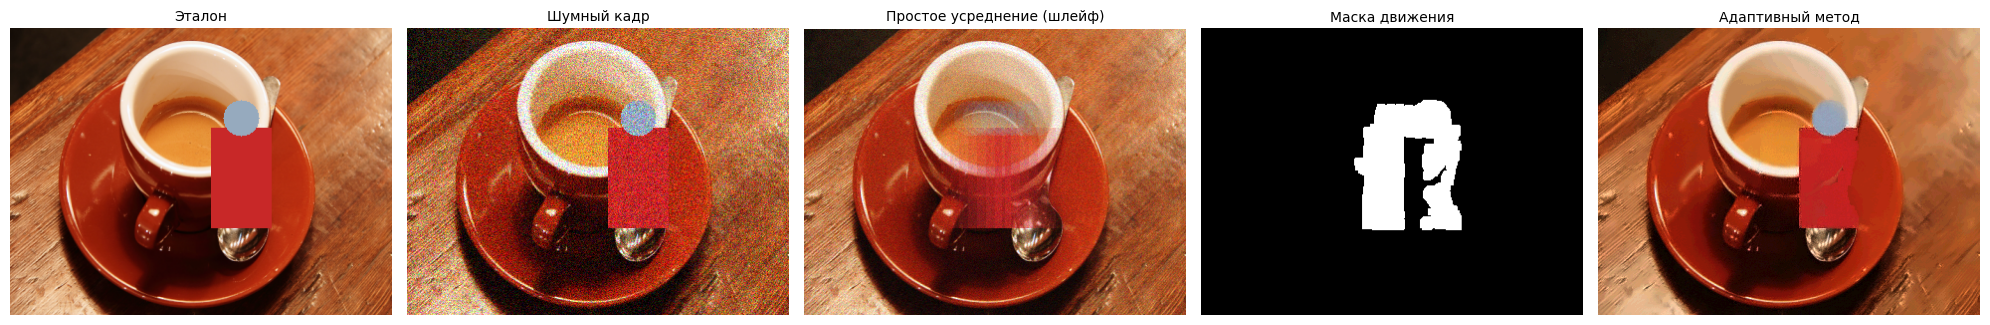

In [8]:
# визуализация: кадр, маска движения, до/после (яркость приведена к норме для наглядности)
t = 20
out, motion = temporal_denoise(noisy_v, t)
naive_out = naive_temporal(noisy_v, t)
panels = [("Эталон", clean[t]), ("Шумный кадр", to_ref_scale(noisy_v[t], BRIGHT)),
          ("Простое усреднение (шлейф)", to_ref_scale(naive_out, BRIGHT)),
          ("Маска движения", motion * 255), ("Адаптивный метод", to_ref_scale(out, BRIGHT))]
fig, axs = plt.subplots(1, 5, figsize=(20, 3.6))
for ax, (title, im) in zip(axs, panels):
    ax.imshow(im if im.ndim == 2 else rgb(im), cmap="gray"); ax.set_title(title, fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()

## 7. Тестирование на разных условиях и нестандартных случаях

Проверяем устойчивость: разная освещённость (от слабо до очень тёмного) и нестандартный случай: **яркий источник света в тёмной сцене**
(фары, фонарь), где адаптивная гамма и CLAHE могут «пересветить» кадр.

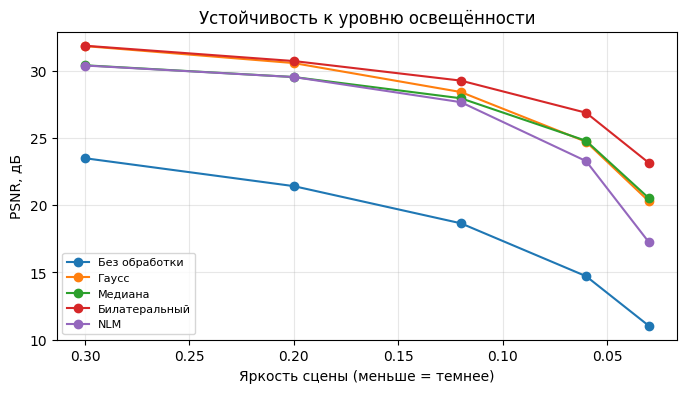

In [9]:
levels = [0.30, 0.20, 0.12, 0.06, 0.03]
img = imgs["chelsea"]
table = {n: [] for n in ["Без обработки"] + list(METHODS)}
for b in levels:
    nz = simulate_low_light(img, b)
    table["Без обработки"].append(quality(img, to_ref_scale(nz, b))[0])
    for n, f in METHODS.items():
        table[n].append(quality(img, to_ref_scale(f(nz), b))[0])

plt.figure(figsize=(8, 4))
for n, v in table.items():
    plt.plot(levels, v, "o-", label=n)
plt.gca().invert_xaxis()
plt.xlabel("Яркость сцены (меньше = темнее)"); plt.ylabel("PSNR, дБ")
plt.title("Устойчивость к уровню освещённости"); plt.legend(fontsize=8); plt.grid(alpha=.3); plt.show()

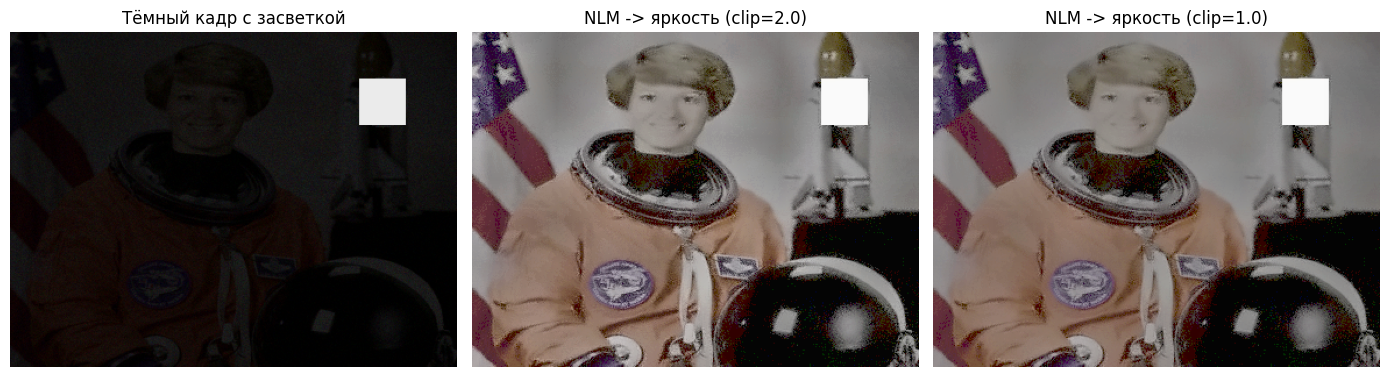

In [10]:
# нестандартный случай: яркий источник света (засветка) в тёмной сцене
img = imgs["astronaut"].copy()
cv2.circle(img, (320, 60), 22, (255, 255, 255), -1)          # "фонарь"
dark = simulate_low_light(img, 0.10)
dark[40:80, 300:340] = np.maximum(dark[40:80, 300:340], 235)  # источник остаётся ярким в тёмном кадре

den = d_nlm(dark, 7)
plain = enhance(den, clip=2.0)         # CLAHE с обычным пределом
safe = enhance(den, clip=1.0)          # более мягкий CLAHE
panels = [("Тёмный кадр с засветкой", dark), ("NLM -> яркость (clip=2.0)", plain), ("NLM -> яркость (clip=1.0)", safe)]
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for ax, (t, im) in zip(axs, panels):
    ax.imshow(rgb(im)); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()

**Наблюдения для отчёта** (дополните по своим графикам):
- На слабом свете PSNR всех методов падает. NLM с **фиксированным** `h=7` (подобран для яркости 0.12) на очень тёмных кадрах проигрывает билатеральному фильтру: сила сглаживания должна соответствовать уровню шума, а он меняется с освещённостью. Это ограничение метода и направление улучшения (автоподбор `h`).
- Яркий источник в кадре «тянет» среднюю яркость вверх, поэтому адаптивная гамма меньше осветляет остальную сцену; снижение `clipLimit` у CLAHE уменьшает артефакты.
- Временное усреднение работает только при неподвижной камере: при дрожании или смене экспозиции ему нужна стабилизация.

## 8. Ваше собственное видео (необязательно)

Загрузите видео из тёмного помещения или с камеры наблюдения (.mp4/.avi). Если файла нет, ячейку можно пропустить.

In [19]:
import subprocess, os

def est_noise(frames):
    m = len(frames) // 2
    a, b = frames[m].astype(np.float32), frames[m - 1].astype(np.float32)
    return float(1.4826 * np.median(np.abs(a - b)) / np.sqrt(2))

def denoise_pro(frames, t, gain, sig, k=11, tau_k=3.0, a_mov=0.9, a_stat=0.45):
    lo, hi = max(0, t - k // 2), min(len(frames), t + k // 2 + 1)
    win = frames[lo:hi]
    cur = frames[t].astype(np.float32)
    blur = lambda f: cv2.GaussianBlur(f, (0, 0), 1.5)
    cs = blur(cur)
    ds = [np.sqrt(((blur(f.astype(np.float32)) - cs) ** 2).sum(2)) for f in win]
    others = np.concatenate([d.ravel() for i, d in zip(range(lo, hi), ds) if i != t])
    tau = max(tau_k * float(np.median(others)), 1e-3) if others.size else 1.0
    num = np.zeros_like(cur); den = np.zeros(cur.shape[:2], np.float32)
    for f, d in zip(win, ds):
        w = np.exp(-(d / tau) ** 2)
        num += w[..., None] * f.astype(np.float32); den += w
    avg = num / den[..., None]
    s = np.clip((den - 1) / max(len(win) - 1, 1), 0, 1)        # 1 = статика, 0 = движение
    s = np.clip((cv2.GaussianBlur(s, (0, 0), 2.0) - 0.4) / 0.4, 0, 1)
    sg = sig * gain
    h_mov = max(1.0, a_mov * sg)
    h_stat = max(1.0, a_stat * sg / np.sqrt(max(1.0, float(den.mean()))))
    boost = lambda x: np.clip(x * gain, 0, 255).round().astype(np.uint8)
    mov = cv2.fastNlMeansDenoisingColored(boost(cur), None, h_mov, h_mov, 7, 21)
    sta = cv2.fastNlMeansDenoisingColored(boost(avg), None, h_stat, h_stat, 7, 21)
    out = s[..., None] * sta.astype(np.float32) + (1 - s[..., None]) * mov.astype(np.float32)
    return np.clip(out, 0, 255).round().astype(np.uint8)

def auto_gain(frames, target=110.0):
    m = np.mean([cv2.cvtColor(f, cv2.COLOR_BGR2GRAY).mean() for f in frames[::5]])
    return float(np.clip(target / max(m, 1.0), 1.0, 15.0))

def process_video(frames, gain=None, k=11):
    gain = auto_gain(frames) if gain is None else gain
    sig = est_noise(frames)
    print(f"оценка шума: {sig:.2f}, усиление яркости: x{gain:.1f}, окно: {k} кадров")
    out = []
    for t in range(len(frames)):
        out.append(denoise_pro(frames, t, gain, sig, k=k))
        if t % 10 == 0: print(f"  кадр {t + 1}/{len(frames)}")
    return out

def beautify(img, clip=1.5):
    l, a, b = cv2.split(cv2.cvtColor(img, cv2.COLOR_BGR2LAB))
    l = cv2.createCLAHE(clipLimit=clip, tileGridSize=(8, 8)).apply(l)
    return cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2BGR)

def save_video(frames, path, fps=15):
    h, w = frames[0].shape[:2]
    tmp = path + ".tmp.avi"
    vw = cv2.VideoWriter(tmp, cv2.VideoWriter_fourcc(*"MJPG"), fps, (w, h))
    for f in frames: vw.write(f)
    vw.release()
    try:
        subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", tmp, "-c:v", "libx264",
                        "-crf", "16", "-pix_fmt", "yuv420p", path], check=True)
        os.remove(tmp)
    except Exception:
        os.replace(tmp, path.replace(".mp4", ".avi")); print("ffmpeg недоступен, сохранён .avi")

Saving WhatsApp Video 2026-10-12 at 14.07.58.mp4 to WhatsApp Video 2026-10-12 at 14.07.58.mp4
кадров: 60
оценка шума: 3.15, усиление яркости: x6.7, окно: 11 кадров
  кадр 1/60
  кадр 11/60
  кадр 21/60
  кадр 31/60
  кадр 41/60
  кадр 51/60
PSNR: шумное 20.45 дБ -> результат 31.23 дБ


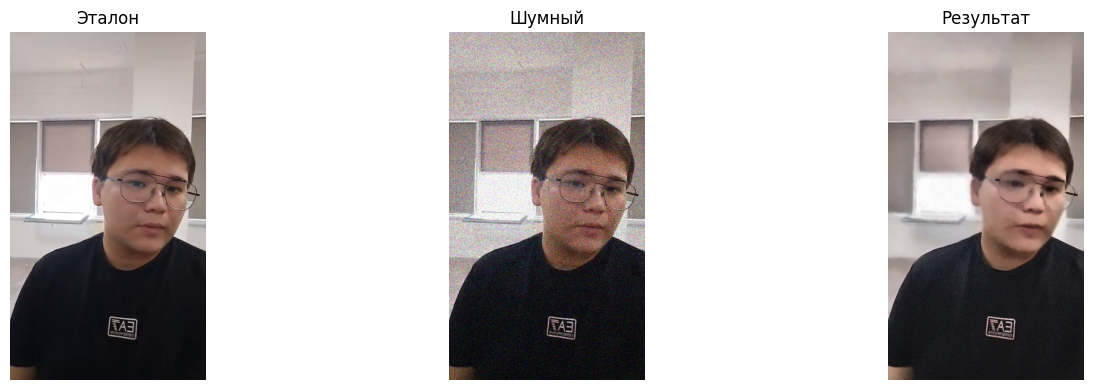

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
from google.colab import files

ADD_NOISE = True      # True: добавить шум к обычному видео; False: видео уже шумное (реальная съёмка)
BRIGHT_V = 0.15       # насколько тёмное (0.05 очень тяжело, 0.25 легко)
MAX_FRAMES = 60

up = files.upload(); path = next(iter(up))
cap = cv2.VideoCapture(path); fps = cap.get(cv2.CAP_PROP_FPS) or 15
clean = []
while len(clean) < MAX_FRAMES:
    ok, f = cap.read()
    if not ok: break
    hh = (int(f.shape[0] * 384 / f.shape[1]) // 2) * 2          # чётная высота для H.264
    clean.append(cv2.resize(f, (384, hh), interpolation=cv2.INTER_AREA))
cap.release()
print("кадров:", len(clean))

noisy = [simulate_low_light(f, BRIGHT_V) for f in clean] if ADD_NOISE else clean
res = process_video(noisy, gain=(1 / BRIGHT_V) if ADD_NOISE else None)

if ADD_NOISE:
    p0 = np.mean([psnr(c, to_ref_scale(n, BRIGHT_V), data_range=255) for c, n in zip(clean, noisy)])
    p1 = np.mean([psnr(c, r, data_range=255) for c, r in zip(clean, res)])
    print(f"PSNR: шумное {p0:.2f} дБ -> результат {p1:.2f} дБ")

show = (lambda x: to_ref_scale(x, BRIGHT_V)) if ADD_NOISE else (lambda x: enhance(x))
side = [np.hstack([show(n), beautify(r)]) for n, r in zip(noisy, res)]
save_video(side, "compare.mp4", fps)                      # слева шумное, справа результат
save_video([beautify(r) for r in res], "result.mp4", fps)
save_video([show(n) for n in noisy], "noisy_bright.mp4", fps)

t = len(res) // 2
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, (title, im) in zip(axs, [("Эталон" if ADD_NOISE else "Вход", clean[t]),
                                  ("Шумный", show(noisy[t])), ("Результат", beautify(res[t]))]):
    ax.imshow(rgb(im)); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

for name in ["compare.mp4", "result.mp4", "noisy_bright.mp4"]:
    files.download(name)

## 9. Выводы

- **Одиночные фильтры:** NLM лучше сохраняет структуру (SSIM), но самый медленный; билатеральный фильтр близок по PSNR и намного быстрее; Гаусс и медиана быстрые, но размывают детали.
- **Для видео с неподвижной камерой** адаптивное временное усреднение с маской движения даёт заметно лучшее качество, чем NLM по отдельным кадрам (на тесте около +2,7 дБ PSNR), и не оставляет «шлейфа» от движущихся объектов (в отличие от простого усреднения). Цена: время на кадр выше, потому что NLM вызывается дважды (для статики и для движения).
- **Порядок важен:** шумоподавление нужно делать до повышения яркости.
- **Ограничения:** метод требует неподвижной камеры, параметры (`h`, `tau`, размер окна) подбираются под уровень шума, при очень слабом свете часть деталей потеряна безвозвратно.
- **Возможные улучшения:** оценка шума по кадру для автоматического `h`, стабилизация камеры перед усреднением, ускорение через уменьшение окна поиска NLM.